<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP10_POSTLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(8*8*128),
    layers.Reshape((8, 8, 128)),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Conv2DTranspose(64, 4, strides=2,
                           padding='same'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Conv2DTranspose(3, 4, strides=2,
                           padding='same',
                           activation='tanh')
])

print("Generator created successfully")

Generator created successfully


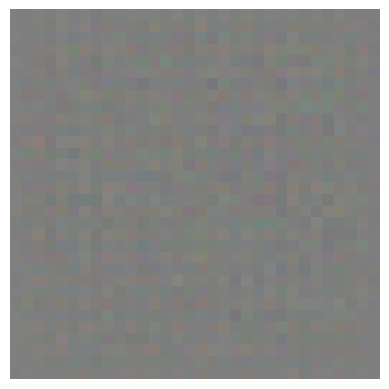

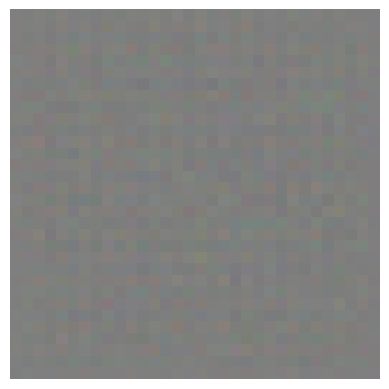

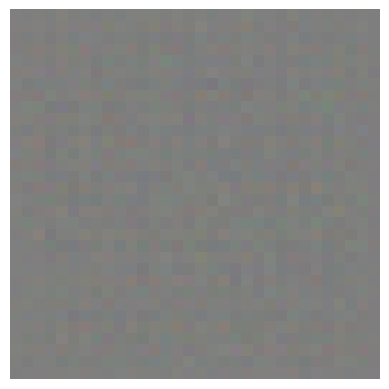

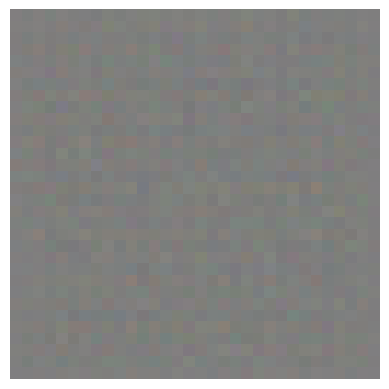

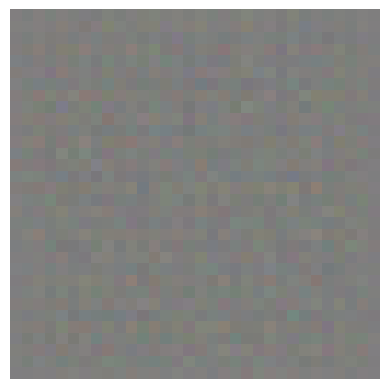

Hinge loss GAN analysis completed


In [3]:
# Generate latent vectors
z1 = tf.random.normal([1, 100])
z2 = tf.random.normal([1, 100])

# Latent space interpolation
for alpha in tf.linspace(0.0, 1.0, 5):
    z = (1-alpha)*z1 + alpha*z2
    img = generator(z)

    plt.imshow((img[0].numpy() + 1) / 2)
    plt.axis('off')
    plt.show()

# Hinge loss
def hinge_loss(real, fake):
    return (tf.reduce_mean(tf.nn.relu(1-real)) +
            tf.reduce_mean(tf.nn.relu(1+fake)))

def gen_loss(fake):
    return -tf.reduce_mean(fake)

print("Hinge loss GAN analysis completed")